![The Bridge - Matplotlib](../img/banner_thebridge_matplotlib.png)

# Visualización con Matplotlib: Extra (opcional)

**Este notebook es opcional.** Recoge técnicas algo más avanzadas que completan lo visto en las sesiones anteriores:

1. Histogramas bidimensionales: ``hist2d`` y ``hexbin``
2. Personalización de las barras de colores (*colorbars*) y elección del mapa de colores
3. Más sobre leyendas: elegir qué elementos aparecen y poner varias leyendas en un mismo gráfico

In [1]:
# %matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-white')

## 1. Histogramas bidimensionales y *binnings*

Al igual que creamos histogramas en una dimensión dividiendo la recta numérica en intervalos, también podemos crear histogramas en dos dimensiones dividiendo los puntos en intervalos bidimensionales.

Empezaremos definiendo unos datos ``x`` e ``y`` extraídos de una distribución gaussiana multivariante:

In [2]:
mean = [0, 0]
cov = [[1, 1], [1, 2]]
x, y = np.random.multivariate_normal(mean, cov, 10000).T

Por separado, cada variable tiene su histograma de toda la vida:

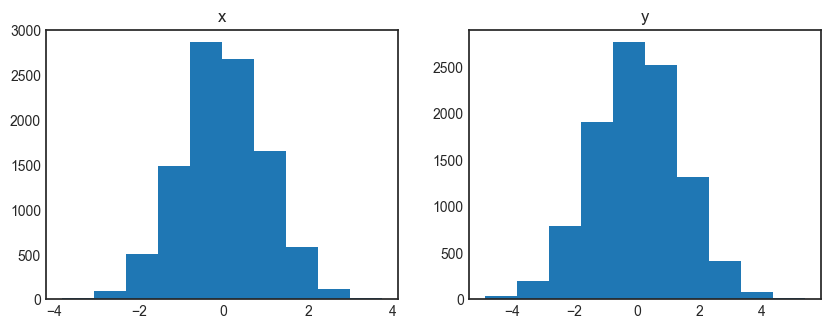

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(x, bins=10)
ax[0].set_title("x")
ax[1].hist(y, bins=10)
ax[1].set_title("y");

### ``plt.hist2d``: histograma bidimensional

Una forma directa de pintar un histograma bidimensional es la función ``plt.hist2d``, que nos muestra cómo se reparten los puntos en el plano:

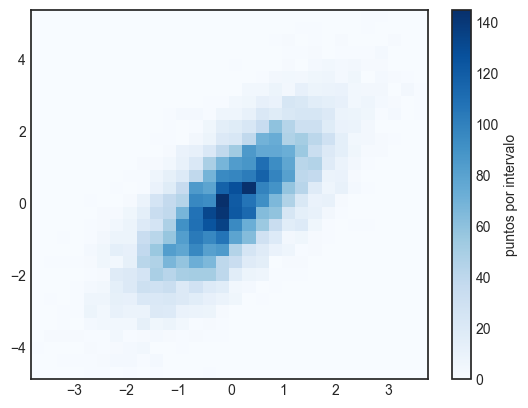

In [4]:
plt.hist2d(x, y, bins=30, cmap='Blues')
cb = plt.colorbar()
cb.set_label('puntos por intervalo');

Al igual que ``plt.hist``, ``plt.hist2d`` tiene una serie de opciones adicionales para ajustar el gráfico y los intervalos, descritas en su documentación.
Y al igual que ``plt.hist`` tiene su equivalente de cálculo en ``np.histogram``, ``plt.hist2d`` lo tiene en ``np.histogram2d``:

In [5]:
counts, xedges, yedges = np.histogram2d(x, y, bins=10)
counts.shape

(10, 10)

Para más de dos dimensiones existe ``np.histogramdd``.

### ``plt.hexbin``: *binnings* hexagonales

El histograma bidimensional divide el plano en cuadrados. Otra forma natural de hacerlo es con hexágonos regulares.
Para ello Matplotlib proporciona ``plt.hexbin``:

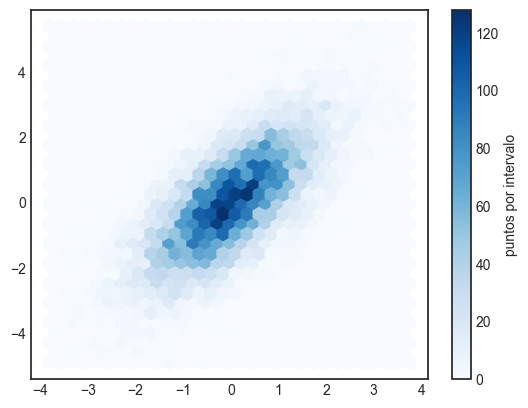

In [6]:
plt.hexbin(x, y, gridsize=30, cmap='Blues')
plt.colorbar(label='puntos por intervalo');

``plt.hexbin`` tiene opciones interesantes, como asignar un peso a cada punto (``C``) y cambiar el valor de cada hexágono por cualquier agregado de NumPy (media de los pesos, desviación estándar, etc.) con ``reduce_C_function``.

## 2. Personalización de las barras de colores

**Las leyendas identifican etiquetas discretas de puntos discretos.
Para valores continuos representados con el color de puntos, líneas o regiones, una barra de colores etiquetada es una gran herramienta.**
En Matplotlib, una barra de colores es un eje aparte que sirve de clave para interpretar los colores de un gráfico.

La barra de colores más sencilla se crea con ``plt.colorbar``:

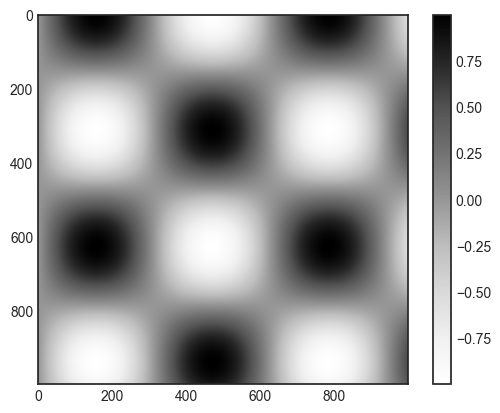

In [7]:
x = np.linspace(0, 10, 1000)
I = np.sin(x) * np.cos(x[:, np.newaxis])

plt.imshow(I)
plt.colorbar();

El mapa de colores se elige con el argumento ``cmap`` de la función que crea la visualización:

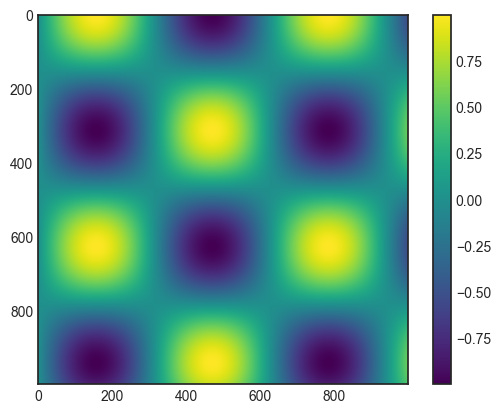

In [8]:
plt.imshow(I, cmap='viridis')
plt.colorbar();

Todos los mapas de colores disponibles están en ``plt.colormaps`` (puedes listarlos con ``list(plt.colormaps)``).
Pero *poder* elegir un mapa de colores es solo el primer paso: lo importante es saber *decidir* entre las posibilidades.

### Elección del mapa de colores

Las pautas para elegir colores en visualización van más allá de este notebook; un buen artículo es ["Ten Simple Rules for Better Figures"](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1003833).
La documentación de Matplotlib también tiene una [interesante discusión](https://matplotlib.org/stable/users/explain/colors/colormaps.html) sobre la elección del mapa de colores.

A grandes rasgos hay tres categorías de mapas de colores:

- **Secuenciales:** una secuencia continua de colores (por ejemplo, ``binary`` o ``viridis``).
- **Divergentes:** dos colores distintos que muestran desviaciones positivas y negativas respecto a un valor central (por ejemplo, ``RdBu`` o ``PuOr``).
- **Cualitativos:** mezclan colores sin una secuencia determinada (por ejemplo, ``rainbow`` o ``jet``).

El mapa ``jet``, que era el predeterminado en Matplotlib antes de la versión 2.0, es un mapa cualitativo.
Era una elección desafortunada, porque los mapas cualitativos suelen ser una mala opción para datos cuantitativos: no muestran una progresión uniforme del brillo a medida que aumenta la escala.

Podemos comprobarlo convirtiendo la barra de colores ``jet`` a blanco y negro:

In [9]:
from matplotlib.colors import LinearSegmentedColormap

def grayscale_cmap(cmap):
    """Devuelve una versión en escala de grises del mapa de colores"""
    cmap = plt.colormaps.get_cmap(cmap)
    colors = cmap(np.arange(cmap.N))

    # convertimos RGBA a luminancia percibida en escala de grises
    # cf. http://alienryderflex.com/hsp.html
    RGB_weight = [0.299, 0.587, 0.114]
    luminance = np.sqrt(np.dot(colors[:, :3] ** 2, RGB_weight))
    colors[:, :3] = luminance[:, np.newaxis]

    return LinearSegmentedColormap.from_list(cmap.name + "_gray", colors, cmap.N)


def view_colormap(cmap):
    """Pinta un mapa de colores junto a su equivalente en escala de grises"""
    cmap = plt.colormaps.get_cmap(cmap)
    colors = cmap(np.arange(cmap.N))

    cmap = grayscale_cmap(cmap)
    grayscale = cmap(np.arange(cmap.N))

    fig, ax = plt.subplots(2, figsize=(6, 2),
                           subplot_kw=dict(xticks=[], yticks=[]))
    ax[0].imshow([colors], extent=[0, 10, 0, 1])
    ax[1].imshow([grayscale], extent=[0, 10, 0, 1])

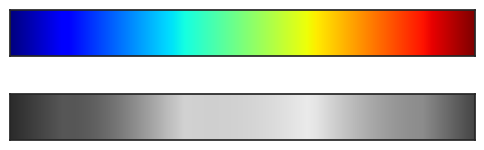

In [10]:
view_colormap('jet')

Fíjate en las franjas brillantes de la imagen en escala de grises.
Incluso a todo color, este brillo desigual hace que el ojo se vaya a ciertas zonas de la gama de colores, lo que puede destacar partes poco importantes de los datos.
Es mejor usar un mapa como ``viridis`` (el predeterminado desde Matplotlib 2.0), construido específicamente para tener una variación de brillo uniforme en toda la gama.
No solo encaja con nuestra percepción del color, sino que además se imprime bien en escala de grises:

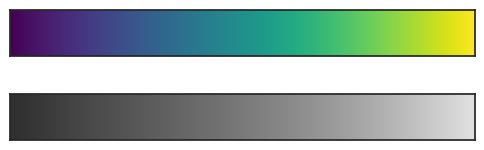

In [11]:
view_colormap('viridis')

Si te gustan los esquemas tipo arco iris, otra buena opción para datos continuos es ``cubehelix``:

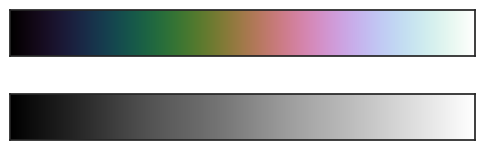

In [12]:
view_colormap('cubehelix')

Para otras situaciones, como mostrar desviaciones positivas y negativas respecto a una media, son útiles los mapas de dos colores como ``RdBu`` (*Rojo-Azul*). Pero ojo: como se ve en la figura, la información positivo/negativo se pierde al pasar a escala de grises.

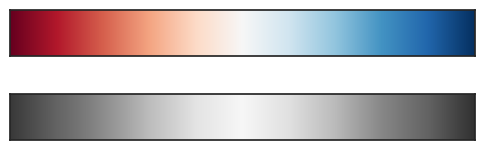

In [13]:
view_colormap('RdBu')

### Límites de color y extensiones

La barra de colores es simplemente una instancia de ``plt.Axes``, así que todos los trucos de formato de ejes que hemos visto le son aplicables.
Por ejemplo, podemos estrechar los límites de color e indicar los valores fuera de rango con una flecha triangular arriba y abajo usando la propiedad ``extend``.
Esto es útil, por ejemplo, cuando la imagen tiene ruido:

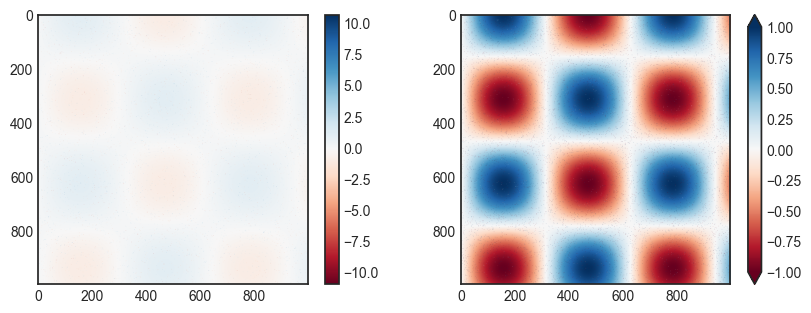

In [14]:
# Metemos ruido en el 1% de los píxeles de la imagen
speckles = (np.random.random(I.shape) < 0.01)
I[speckles] = np.random.normal(0, 3, np.count_nonzero(speckles))

plt.figure(figsize=(10, 3.5))

plt.subplot(1, 2, 1)
plt.imshow(I, cmap='RdBu')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(I, cmap='RdBu')
plt.colorbar(extend='both')  # extremos triangulares en la barra
plt.clim(-1, 1);             # fijamos los límites de color

En el panel izquierdo los límites de color por defecto se ajustan a los píxeles *ruidosos*, y el rango del ruido borra por completo el patrón que nos interesa.
En el derecho fijamos a mano los límites de color y añadimos extensiones para indicar los valores que quedan por encima o por debajo.
El resultado es una visualización mucho más útil.

### Barras de colores discretas

Los mapas de colores son continuos por defecto, pero a veces queremos representar valores discretos.
La forma más sencilla es usar ``plt.get_cmap()`` pasando el nombre del mapa y el número de intervalos deseados:

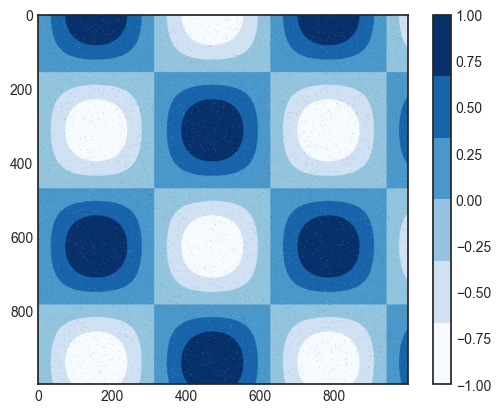

In [15]:
plt.imshow(I, cmap=plt.get_cmap('Blues', 6))
plt.colorbar()
plt.clim(-1, 1);

La versión discreta de un mapa de colores se usa igual que cualquier otro mapa.

## 3. Más sobre leyendas

### Elegir los elementos de la leyenda

Por defecto la leyenda incluye todos los elementos con etiqueta.
Si no es lo que queremos, podemos elegir qué elementos y etiquetas aparecen usando los objetos que devuelven las funciones de dibujo.
``plt.plot()`` puede crear varias líneas a la vez y devuelve una lista con ellas.
Si pasamos algunas a ``plt.legend()`` le decimos cuáles identificar, junto con las etiquetas que queramos:

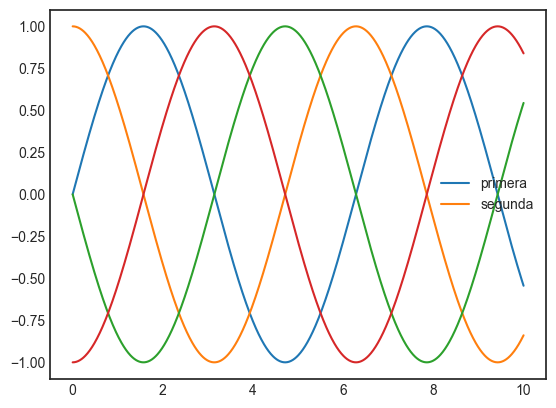

In [16]:
x = np.linspace(0, 10, 1000)
y = np.sin(x[:, np.newaxis] + np.pi * np.arange(0, 2, 0.5))
lines = plt.plot(x, y)

# lines es una lista de objetos plt.Line2D
plt.legend(lines[:2], ['primera', 'segunda']);

En la práctica suele ser más claro el primer método: poner etiqueta (``label``) solo a los elementos que queremos ver en la leyenda, ya que la leyenda ignora los elementos sin etiqueta:

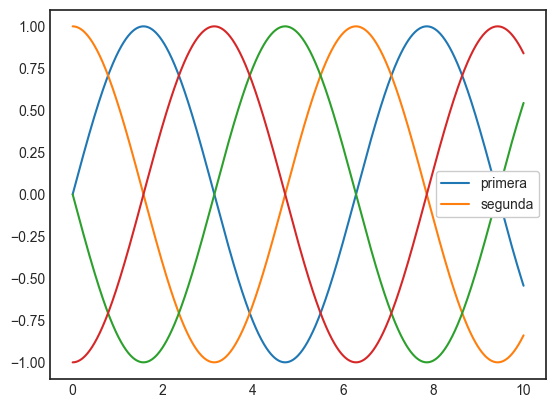

In [17]:
plt.plot(x, y[:, 0], label='primera')
plt.plot(x, y[:, 1], label='segunda')
plt.plot(x, y[:, 2:])
plt.legend(framealpha=1, frameon=True);

### Varias leyendas

A veces queremos añadir varias leyendas a los mismos ejes.
Matplotlib no lo pone fácil: con ``plt.legend()`` o ``ax.legend()`` solo se puede crear una leyenda, y **si intentas crear una segunda simplemente sustituye a la primera.**
La solución es crear un nuevo objeto ``Legend`` desde cero y añadirlo manualmente al gráfico con el método de bajo nivel ``ax.add_artist()``:

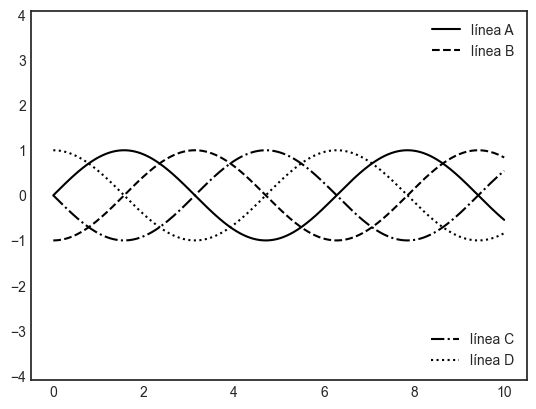

In [18]:
fig, ax = plt.subplots()

lines = []
styles = ['-', '--', '-.', ':']
x = np.linspace(0, 10, 1000)

for i in range(4):
    lines += ax.plot(x, np.sin(x - i * np.pi / 2),
                     styles[i], color='black')
ax.axis('equal')

# líneas y etiquetas de la primera leyenda
ax.legend(lines[:2], ['línea A', 'línea B'],
          loc='upper right', frameon=False)

# creamos la segunda leyenda y la añadimos a mano
from matplotlib.legend import Legend
leg = Legend(ax, lines[2:], ['línea C', 'línea D'],
             loc='lower right', frameon=False)
ax.add_artist(leg);

Esto es un vistazo a los objetos de bajo nivel (*artists*) que componen cualquier gráfico de Matplotlib.
Si examinas el código fuente de ``ax.legend()`` (en un notebook puedes hacerlo con ``ax.legend??``) verás que la función se limita a crear un objeto ``Legend`` adecuado, que se guarda en el atributo ``legend_`` y se añade a la figura al dibujarla.